# RL Post-Training — 0 : le reward model from scratch (Bradley-Terry)

**Série RL Post-Training** (`rlpt_*`) — cette série explore l'**alignement** de modèles de langage
sur un signal de préférence (RLHF, GRPO, DPO). Le pipeline complet d'InstructGPT comporte trois
étages : collecter des **comparaisons humaines**, en **entraîner un reward model**, puis optimiser
la politique contre ce reward model sous contrainte KL.

`RLPT-01` commence directement au troisième étage avec un reward model **jouet codé en dur**
(`rm(seq, prompt)` : `+1` si `a` en position 1 pour le prompt A, `e` en position 5 pour le prompt
B). Ce notebook est l'étage manquant, numéroté 0 parce qu'il le précède : **d'où vient le reward
quand personne ne peut l'écrire ?** Réponse : on l'apprend à partir de paires de préférences.

Le fil conducteur est le formalisme de **Bradley-Terry (1952)**, adapté aux préférences par
Christiano et al. (2017) puis Ouyang et al. (2022) :

$$P(y_w \succ y_l \mid x) = \sigma\big(r_\theta(x, y_w) - r_\theta(x, y_l)\big)$$

où $y_w$ (winning) et $y_l$ (losing) sont deux réponses au même prompt $x$, $\sigma$ la sigmoïde
et $r_\theta$ un réseau à tête scalaire. L'entraînement maximise la vraisemblance des choix
observés — exactement une régression logistique sur les **différences** de reward.

**Prérequis** : PyTorch de base (`RL-06`), le concept de reward (`RL-01`, `RL-05`). Dépendances CPU : `torch`, `numpy`, `matplotlib` et `scipy` : tout est from scratch, CPU, déterministe
(multi-seed `[0, 1, 7, 42]`, convention review C).

**Plan** : un monde synthétique avec un reward *vrai* connu (§2), un juge qui choisit entre deux
réponses selon Bradley-Terry (§3), un reward model entraîné par MLE (§4-6), et une évaluation
*honnête* — plafond de Bayes, calibration, identification par prompt (§7-10). Trois exercices clôturent
le notebook.

**Navigation** : [Index RL](../README.md) | [Version C#](RLPT-00-Reward-Model-Bradley-Terry-CSharp.ipynb) | [RLPT-00b](RLPT-00b-Biais-Dataset-Preferences-Python.ipynb)

**Durée estimée** : 90 minutes.

**Objectifs pédagogiques** : entraîner un modèle Bradley–Terry, évaluer accuracy, Brier et calibration face aux références de Bayes, puis identifier les limites de l’architecture et des comparaisons intra-prompt.

## 1. Le problème : noter est dur, comparer est facile

En RL classique, le reward est **donné** par l'environnement (gagner la partie, atteindre le but).
Pour aligner un modèle de langage, personne ne sait écrire $r(\text{« bonne réponse »})$. L'exploit
du RLHF (Christiano et al. 2017) est un déplacement : les humains ne savent pas **noter** une
réponse sur une échelle, mais savent très bien **comparer** deux réponses au même prompt.

Le contrat est donc :

| Ce qui existe | Ce qu'on veut |
|---|---|
| Des paires $(y_w, y_l)$ — « je préfère celle-ci à celle-là » | Une fonction $r_\theta(x, y)$ utilisable comme reward par PPO/GRPO (`RLPT-01`) |

Bradley-Terry transforme les préférences en probabilités : la paire fournit une observation bruitée dont la probabilité dépend de la différence des scores. C'est
une hypothèse de **rationalité du juge** — on verra précisément ce qu'elle vaut dans le monde
synthétique, où le vrai reward est connu et donc mesurable.

**Pourquoi un monde synthétique ?** Sur des données réelles, on ne peut pas mesurer l'erreur du
reward model (personne ne connaît $r^*$). Ici, $r^*$ est connu par construction : on peut calculer
la **référence de Bayes** (accuracy optimale en espérance conditionnelle, pour ces entrées et ce juge stochastique), le plancher de Brier, et la corrélation $\hat r$ vs $r^*$. C'est la
différence entre *évaluer* un reward model et *prouver* qu'il est honnête.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(0)
SEEDS = [0, 1, 7, 42]          # multi-seed (convention pr-review C)
LEN_R = 8                      # longueur de la reponse (comme rlpt_1)
TOK = ['<pA>', '<pB>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
V = {c: i for i, c in enumerate(TOK)}
DEV = 'cpu'

print(f"vocabulaire : {len(TOK)} tokens ({TOK[2:]} + prompts {TOK[:2]})")
print(f"reponse de {LEN_R} tokens, seeds {SEEDS}, device {DEV}")
print(f"PyTorch {torch.__version__}; NumPy {np.__version__}; threads CPU {torch.get_num_threads()}")

vocabulaire : 10 tokens (['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'] + prompts ['<pA>', '<pB>'])
reponse de 8 tokens, seeds [0, 1, 7, 42], device cpu
PyTorch 2.10.0+cpu; NumPy 2.4.4; threads CPU 1


## 2. Le monde synthétique : une oracle graduée

On reprend le monde de `RLPT-01` à l'identique — vocabulaire de 8 tokens de contenu `a`..`h`, deux
prompts `<pA>`/`<pB>`, réponses de 8 tokens — mais son oracle binaire (`0`/`1`) est remplacée par
une version **graduée**, prolongement naturel de la même structure :

- **poids par token** $w(t)$ : `a` porteur (+0.30), `e` porteur (+0.25), ... `h` bruit (−0.20) ;
- **bonus positionnel conditionné au prompt** : +0.80 si le prompt A reçoit `a` en position 1,
  +0.80 si le prompt B reçoit `e` en position 5 — exactement la structure de l'oracle de `RLPT-01`,
  en version continue.

Pourquoi graduer ? Parce que Bradley-Terry a besoin d'une **échelle** : avec un reward binaire,
toutes les paires non-ex-aequo ont la même différence $\Delta r^* = 1$, et le modèle de
préférence n'a rien à apprendre au-delà d'un classement à deux niveaux. Le reward gradué donne à
$\sigma(\Delta r)$ une plage complète de probabilités — c'est ce qui rend la *calibration*
(section 8) mesurable.

Le reward vrai d'une réponse est donc :

$$r^*(y \mid x) = \sum_{t \in y} w(t) + 0.8 \cdot \mathbb{1}[x = A,\ y_1 = a] + 0.8 \cdot \mathbb{1}[x = B,\ y_5 = e]$$

In [2]:
W_TOK = {'a': 0.30, 'b': 0.05, 'c': 0.10, 'd': 0.15,
         'e': 0.25, 'f': -0.10, 'g': -0.15, 'h': -0.20}


def true_reward(seq, prompt):
    """Oracle graduate : somme des poids de tokens + bonus positionnel conditionne au prompt.
    (rlpt_1 code cette structure en 0/1 ; ici elle est continue pour donner une echelle a BT.)"""
    r = sum(W_TOK[TOK[t]] for t in seq)
    if prompt == 0 and seq[0] == V['a']:
        r += 0.8
    if prompt == 1 and seq[4] == V['e']:
        r += 0.8
    return r


def seq_str(seq):
    return ' '.join(TOK[i] for i in seq)


# Exemples : scorer des reponses aux deux prompts
exemples = [
    ([V['a']] + [V['h']] * 7, 0),                    # 'a' en pos1 pour A : bonus + poids
    ([V['h']] * 8, 0),                               # que du bruit pour A
    ([V['b']] * 4 + [V['e']] + [V['b']] * 3, 1),     # 'e' en pos5 pour B : bonus
    ([V['a'], V['c'], V['d'], V['a'], V['b'], V['e'], V['g'], V['c']], 0),  # mixte
]
for seq, p in exemples:
    print(f"prompt {TOK[p]:<4} | {seq_str(seq):<23} -> r* = {true_reward(seq, p):+.2f}")

# Plage du reward vrai sur reponses uniformes
rng_u = np.random.default_rng(0)
rs_u = [true_reward(rng_u.integers(2, len(TOK), size=LEN_R), int(rng_u.integers(0, 2)))
        for _ in range(2000)]
print(f"\nr* sur 2000 reponses uniformes : min {min(rs_u):+.2f}, max {max(rs_u):+.2f}, "
      f"moyenne {np.mean(rs_u):+.2f}, ecart-type {np.std(rs_u):.2f}")

prompt <pA> | a h h h h h h h         -> r* = -0.30
prompt <pA> | h h h h h h h h         -> r* = -1.60
prompt <pB> | b b b b e b b b         -> r* = +1.40
prompt <pA> | a c d a b e g c         -> r* = +1.90

r* sur 2000 reponses uniformes : min -1.25, max +2.65, moyenne +0.51, ecart-type 0.60


## 3. Le juge : des préférences selon Bradley-Terry

Le **seul signal observable** n'est pas $r^*$ mais des choix binaires. Le juge (l'« humain »
simulé) reçoit deux réponses au même prompt et choisit :

$$P(y_a \succ y_b \mid x) = \sigma\big(\beta \,(r^*(y_a \mid x) - r^*(y_b \mid x))\big), \qquad \beta = 1$$

Deux choix de conception à noter :

1. **Paires à même prompt.** Comparer des réponses à des prompts différents n'a pas de sens (une
   réponse n'est bonne *que* relativement à sa question) — c'est aussi la contrainte du monde
   réel, où les plateformes de labeling présentent deux réponses au même prompt.
2. **Paires écartées si $|\Delta r^*| < 0.3$.** Un juge confronté à deux réponses quasi équivalentes
   répond à pile ou face ; ces paires ne contiennent presque pas de signal et diluent le dataset.
   Le monde réel fait de même : les comparaisons trop ambiguës sont bruitées pour l'annotateur.

L'**étiquette** est tirée de Bernoulli($P$) : le juge est *rationnel mais stochastique*. Ce détail
gouverne toute l'évaluation — même un reward model parfait commettra des « erreurs » sur les paires
où le juge s'est trompé. La référence de Bayes (section 7) quantifie cette limite en espérance, pas une borne dure sur une réalisation finie.

In [3]:
def sample_response(rng):
    """Reponse uniforme sur les tokens de contenu 'a'..'h' (politique aleatoire, comme un
    modele SFT non aligne qui n'a encore aucune raison de preferer un token)."""
    return rng.integers(2, len(TOK), size=LEN_R)


def make_pairs(n_pairs, rng, min_gap=0.3, beta=1.0, prob_fn=None):
    """Paires (a, b) au meme prompt + etiquettes BT vraies.
    y = 1 : le juge a choisi 'a' ; y = 0 : il a choisi 'b'."""
    pw, y, rs, pr = [], [], [], []
    while len(pw) < n_pairs:
        prompt = int(rng.integers(0, 2))
        a, b = sample_response(rng), sample_response(rng)
        ra, rb = true_reward(a, prompt), true_reward(b, prompt)
        if abs(ra - rb) < min_gap:
            continue                      # paire quasi ex aequo : pas de signal
        p_a = 1.0 / (1.0 + np.exp(-beta * (ra - rb))) if prob_fn is None else float(prob_fn(ra - rb, beta))
        if not np.isfinite(p_a) or not 0 <= p_a <= 1:
            raise ValueError("Probabilité du juge invalide")
        pw.append((a, b))
        y.append(1 if rng.random() < p_a else 0)
        rs.append((ra, rb))
        pr.append(prompt)
    return pw, np.array(y), np.array(rs), np.array(pr)


rng = np.random.default_rng(0)
train_pairs, y_train, rs_train, pr_train = make_pairs(4000, rng)
test_pairs, y_test, rs_test, pr_test = make_pairs(1000, rng)
print(f"train : {len(train_pairs)} paires | test : {len(test_pairs)} paires")

i = 3
pa, pb = train_pairs[i]
print(f"\nexemple paire {i} (prompt {TOK[pr_train[i]]}) :")
print(f"  a : {seq_str(pa):<23} r* = {rs_train[i][0]:+.2f}")
print(f"  b : {seq_str(pb):<23} r* = {rs_train[i][1]:+.2f}")
print(f"  juge : choisit {'a' if y_train[i] else 'b'} "
      f"(P(a) = {1/(1+np.exp(-(rs_train[i][0]-rs_train[i][1]))):.2f})")

train : 4000 paires | test : 1000 paires

exemple paire 3 (prompt <pB>) :
  a : h f g f f d h b         r* = -0.65
  b : e f g e d c d d         r* = +0.80
  juge : choisit b (P(a) = 0.19)


### Statistiques du juge

Les quantiles et taux ci-dessous résument les paires générées.

In [4]:
# Statistiques du dataset : le juge est-il rationnel au sens de BT ?
d_tr = rs_train[:, 0] - rs_train[:, 1]
d_te = rs_test[:, 0] - rs_test[:, 1]
p_te = 1.0 / (1.0 + np.exp(-d_te))

print("Delta r* (train) en quantiles :")
for q in [0, 10, 25, 50, 75, 90, 100]:
    print(f"  q{q:>3} : {np.percentile(d_tr, q):+.2f}")

accord_test = float(np.mean((d_te > 0) == (y_test == 1)))
print(f"\ntaux d'accord juge vs signe de Delta r* (test) : {accord_test:.3f}")
print(f"plafond de Bayes empirique E[max(p, 1-p)] (test) : {np.mean(np.maximum(p_te, 1 - p_te)):.3f}")
print(f"proportion de labels y=1 : {np.mean(y_train):.3f} (symetrie attendue ~0.5)")

Delta r* (train) en quantiles :
  q  0 : -2.95
  q 10 : -1.25
  q 25 : -0.75
  q 50 : +0.30
  q 75 : +0.80
  q 90 : +1.25
  q100 : +2.85

taux d'accord juge vs signe de Delta r* (test) : 0.705
plafond de Bayes empirique E[max(p, 1-p)] (test) : 0.702
proportion de labels y=1 : 0.499 (symetrie attendue ~0.5)


**Lecture des statistiques.** Le tableau mesure le taux d'accord réalisé du juge, la référence de Bayes en espérance conditionnelle et les quantiles. Une accuracy réalisée sur un échantillon fini peut dépasser cette référence par fluctuation.

## 4. Encodage : une paire = deux séquences `[prompt] + réponse`

Le reward model de la littérature note la **paire** $(x, y)$ — il est conditionné au prompt, comme
l'oracle. On encode chaque réponse en **9 tokens** : le token de prompt en position 0, la réponse
en positions 1..8, exactement la mise en page de la politique de `RLPT-01` (`x = [prompt, y_1..y_8]`).

Une paire devient un tenseur `(B, 2, 9)` : deux « bras » que le modèle note indépendamment. La
perte BT ne voit jamais les scores absolus séparément — seulement leur **différence** — c'est le
cœur de la section 10.

In [5]:
def encode(pair_list, prompt_list):
    """Liste de paires -> tenseur (B, 2, 1+LEN_R) : prompt en pos 0, reponse en 1..8."""
    B = len(pair_list)
    x = torch.zeros(B, 2, 1 + LEN_R, dtype=torch.long)
    for i, (a, b) in enumerate(pair_list):
        x[i, 0, 0] = prompt_list[i]         # reponse 'a' : son prompt
        x[i, 0, 1:] = torch.from_numpy(np.asarray(a, dtype=np.int64))
        x[i, 1, 0] = prompt_list[i]         # reponse 'b' : le meme prompt
        x[i, 1, 1:] = torch.from_numpy(np.asarray(b, dtype=np.int64))
    return x


x_train, x_test = encode(train_pairs, pr_train), encode(test_pairs, pr_test)
print(f"x_train : {tuple(x_train.shape)} | x_test : {tuple(x_test.shape)}")

# Verif : decodage de la premiere paire encodee
i = 0
for bras in range(2):
    ids = x_train[i, bras].tolist()
    print(f"bras {'ab'[bras]} : [{TOK[ids[0]]}] {seq_str(ids[1:])}")

x_train : (4000, 2, 9) | x_test : (1000, 2, 9)
bras a : [<pB>] f e c c a a a b
bras b : [<pB>] g f h e e h f f


## 5. Le reward model : embedding + position + pooling + tête scalaire

La séquence de neuf tokens passe par `Embedding(10,64)` et `Embedding(9,64)`, puis moyenne et MLP 64→64 ReLU→1 : **5 441 paramètres**. La somme des embeddings de position est constante à longueur fixe. Le pooling est donc invariant aux permutations du contenu et ne peut pas apprendre le bonus dépendant de la position, même si les positions sont encodées. La cellule vérifie ce contre-exemple.

In [6]:
class RewardModel(nn.Module):
    """Squelette de CharPolicy (rlpt_1) avec tete scalaire : emb(tok)+emb(pos) -> pool -> MLP."""

    def __init__(self, vs=len(TOK), hid=64):
        super().__init__()
        self.emb = nn.Embedding(vs, hid)
        self.pos = nn.Embedding(1 + LEN_R, hid)
        self.mlp = nn.Sequential(nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))

    def forward(self, x):                    # x : (B, 1+LEN_R), prompt en pos 0
        L = x.shape[1]
        h = self.emb(x) + self.pos(torch.arange(L))
        return self.mlp(h.mean(1)).squeeze(-1)   # (B,)


def count_params(m):
    return sum(p.numel() for p in m.parameters())


model = RewardModel()
print(f"parametres : {count_params(model)}")

# Avant apprentissage : scores quasi uniformes (initialisation aleatoire)
with torch.no_grad():
    x_ex = torch.tensor([[p] + list(seq) for seq, p in exemples], dtype=torch.long)
    r_init = model(x_ex)
for (seq, p), r in zip(exemples, r_init.tolist()):
    print(f"prompt {TOK[p]:<4} r* = {true_reward(seq, p):+.2f} -> r_hat initial = {r:+.3f}")
# Même prompt et même multiensemble : la position seule change l'oracle.
q1 = [V['a']] + [V['h']] * 7
q2 = [V['h'], V['a']] + [V['h']] * 6
with torch.no_grad():
    scores_perm = model(torch.tensor([[0]+q1,[0]+q2],dtype=torch.long)).numpy()
delta_oracle = true_reward(q1,0) - true_reward(q2,0)
assert abs(delta_oracle - .8) < 1e-12 and abs(scores_perm[0]-scores_perm[1]) < 1e-6
print(f"Permutation : delta oracle={delta_oracle:.3f}, delta modèle={scores_perm[0]-scores_perm[1]:.3e}")

parametres : 5441
prompt <pA> r* = -0.30 -> r_hat initial = -0.132
prompt <pA> r* = -1.60 -> r_hat initial = -0.116
prompt <pB> r* = +1.40 -> r_hat initial = -0.055
prompt <pA> r* = +1.90 -> r_hat initial = -0.102
Permutation : delta oracle=0.800, delta modèle=-2.980e-08


## 6. Entraînement : vraisemblance de Bradley–Terry

La perte de Bradley-Terry sur une paire est la **négative log-vraisemblance du choix observé** :

$$\mathcal{L}(y_w, y_l) = -\log \sigma\big(\hat r(x, y_w) - \hat r(x, y_l)\big)$$

En code, c'est une *binary cross-entropy avec logits* où la cible est toujours 1 — le couple
(gagnant, perdant) est réordonné pour que le logits soit toujours « le gagnant moins le perdant ».
C'est la même perte que la régression logistique binaire, appliquée à des différences de scores
de réseau. Pour un logit gagnant moins perdant noté z, sa dérivée vaut σ(z)−1 : son amplitude tend vers zéro lorsque la préférence observée est déjà prédite avec forte confiance. Sur des préférences bruitées, le minimum attendu reproduit les probabilités conditionnelles ; ce mécanisme ne prouve donc pas une surconfiance structurelle.

Le label `y=1` désigne le bras 0 du tenseur : `winner=1-y`, `loser=y`. Le signe du score et les métriques de test doivent être contrôlés, car une indexation inversée entraîne bien une perte mais sur les préférences opposées.

Adam utilise 60 époques et des batches de 256 paires.


In [7]:
def train_bt(model, x, y, epochs=60, bs=256, lr=1e-2, verbose=False, penalty=None, lam=0.):
    """MLE Bradley-Terry par mini-lots. x : (N, 2, 1+LEN_R), y : (N,) dans {0, 1}."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(y)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(n).tolist()
        tot = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb = x[idx]                             # (b, 2, 9)
            yb = torch.tensor(y[idx], dtype=torch.long)
            b = len(idx)
            win = xb[torch.arange(b), 1 - yb]       # y=1 -> 'a' gagne = bras 0
            lose = xb[torch.arange(b), yb]          # y=1 -> 'b' perd  = bras 1
            rw, rl = model(win), model(lose)
            loss = F.binary_cross_entropy_with_logits(rw - rl, torch.ones(b))
            if penalty is not None:
                loss = loss + penalty(rw, rl, lam)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * b
        hist.append(tot / n)
        if verbose and (ep % 15 == 0 or ep == epochs - 1):
            print(f"  epoch {ep:>3} : perte BT = {hist[-1]:.4f}")
    return hist


torch.manual_seed(0)
model = RewardModel()
hist = train_bt(model, x_train, y_train, verbose=True)
print(f"\nperte : {hist[0]:.4f} -> {hist[-1]:.4f} "
      f"(log 2 = {np.log(2):.4f} = niveau du choix au hasard)")

  epoch   0 : perte BT = 0.6202


  epoch  15 : perte BT = 0.5943


  epoch  30 : perte BT = 0.5864


  epoch  45 : perte BT = 0.5785


  epoch  59 : perte BT = 0.5738

perte : 0.6202 -> 0.5738 (log 2 = 0.6931 = niveau du choix au hasard)


## 7. Évaluation : références de Bayes

Pour $p=\sigma(\Delta r^*)$, l'accuracy optimale conditionnelle **en espérance** est $E[\max(p,1-p)]$ et le Brier Bayes est $E[p(1-p)]$. Une réalisation finie peut dépasser la première. La NLL oracle réalisée et l'entropie attendue sont deux quantités distinctes ; l'écart train/test est un diagnostic, non une preuve de surapprentissage.

In [8]:
def predict_pairs(model, x, y):
    """Scores et metriques held-out sur les paires encodees x, etiquettes y."""
    with torch.no_grad():
        r_hat = model(x.reshape(-1, 1 + LEN_R)).numpy().reshape(len(y), 2)
    ra, rb = r_hat[:, 0], r_hat[:, 1]
    p_hat = 1.0 / (1.0 + np.exp(-(ra - rb)))
    acc = float(np.mean((ra > rb) == (y == 1)))
    brier = float(np.mean((p_hat - y) ** 2))
    return r_hat, p_hat, acc, brier


# Bornes de Bayes depuis le reward vrai (le juge ne peut pas se deviner lui-meme)
d_te = rs_test[:, 0] - rs_test[:, 1]
p_true = 1.0 / (1.0 + np.exp(-d_te))
acc_bayes = float(np.mean(np.maximum(p_true, 1 - p_true)))
brier_bayes = float(np.mean(p_true * (1 - p_true)))
nll_bayes = float(np.mean(-(y_test * np.log(p_true + 1e-12) + (1 - y_test) * np.log(1 - p_true + 1e-12))))

r_hat, p_hat, acc, brier = predict_pairs(model, x_test, y_test)
_, _, acc_train, _ = predict_pairs(model, x_train, y_train)
nll_test = float(np.mean(-(y_test*np.log(p_hat+1e-12)+(1-y_test)*np.log(1-p_hat+1e-12))))
entropy_test = float(np.mean(-(p_true*np.log(p_true+1e-12)+(1-p_true)*np.log(1-p_true+1e-12))))
from scipy.stats import spearmanr
rho, _ = spearmanr(r_hat.flatten(), rs_test.flatten())

print(f"{'metrique':<34}{'modele':>10}{'reference':>12}")
print(f"{'accuracy paires (test)':<34}{acc:>10.3f}{acc_bayes:>12.3f}  <- référence Bayes en espérance")
print(f"{'accuracy paires (train)':<34}{acc_train:>10.3f}{'':>12}  <- diagnostic train/test")
print(f"{'Brier (test)':<34}{brier:>10.4f}{brier_bayes:>12.4f}  <- plancher Bayes")
print(f"NLL train={hist[-1]:.4f}; NLL modèle test={nll_test:.4f}; NLL oracle réalisée test={nll_bayes:.4f}; entropie attendue={entropy_test:.4f}")
print(f"{'Spearman r_hat vs r* (test)':<34}{rho:>10.3f}{'1.000':>12}")
print(f"\necart au plafond : {acc_bayes - acc:+.3f} | ecarts 2x : {acc_train - acc:+.3f} (train-test)")

metrique                              modele   reference
accuracy paires (test)                 0.665       0.702  <- référence Bayes en espérance
accuracy paires (train)                0.704              <- diagnostic train/test
Brier (test)                          0.2259      0.2012  <- plancher Bayes
NLL train=0.5738; NLL modèle test=0.6565; NLL oracle réalisée test=0.5835; entropie attendue=0.5888
Spearman r_hat vs r* (test)            0.800       1.000

ecart au plafond : +0.037 | ecarts 2x : +0.038 (train-test)


**Lecture du tableau.** L'accuracy réalisée se compare à la référence en espérance, et le Brier du modèle à $E[p(1-p)]$. Le tableau donne aussi NLL train, NLL test, NLL oracle réalisée et entropie attendue : leur comparaison renseigne sans prouver à elle seule une cause. Spearman global agrège deux prompts dont les offsets ne sont pas identifiés.

Sur ce run, accuracy test **0,665** contre référence attendue **0,702** ; Brier **0,2259** contre **0,2012**. NLL modèle test **0,6565** et entropie attendue **0,5888** : des écarts à interpréter avec la capacité et le bruit.

## 8. Calibration : diagramme de fiabilité

Chaque point est un décile non vide : probabilité moyenne prédite contre fréquence observée. La diagonale $y=x$ représente la calibration parfaite ; l'ECE pondère les écarts par les effectifs. Le bruit fini, la capacité et l'optimisation peuvent contribuer aux écarts.

decile     n  confiance  observe
     0    49      0.066    0.204
     1   110      0.155    0.282
     2   107      0.249    0.374
     3   123      0.347    0.350
     4    97      0.448    0.464
     5   122      0.548    0.615
     6   125      0.650    0.648
     7   123      0.745    0.683
     8    95      0.850    0.737
     9    49      0.940    0.776

ECE = 0.0707 | confiance moyenne 0.719 vs accuracy 0.665 (sur-confiance si confiance > accuracy)


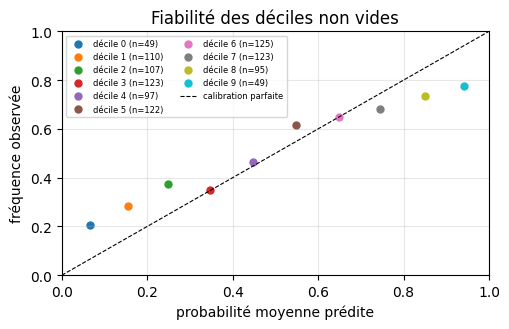

In [9]:
deciles = np.minimum((p_hat * 10).astype(int), 9)
rows = []
for k in range(10):
    m = deciles == k
    if m.sum() == 0:
        continue
    rows.append((k, m.sum(), float(np.mean(p_hat[m])), float(np.mean(y_test[m]))))

print(f"{'decile':>6}{'n':>6}{'confiance':>11}{'observe':>9}")
for k, n, conf, obs in rows:
    print(f"{k:>6}{n:>6}{conf:>11.3f}{obs:>9.3f}")

ece = sum(n * abs(conf - obs) for _, n, conf, obs in rows) / len(y_test)
conf_moy = float(np.mean(np.maximum(p_hat, 1 - p_hat)))
print(f"\nECE = {ece:.4f} | confiance moyenne {conf_moy:.3f} vs accuracy {acc:.3f} "
      f"(sur-confiance si confiance > accuracy)")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
for k, n, conf, obs in rows:
    ax.scatter(conf, obs, s=25, label=f"décile {k} (n={n})")
ax.plot([0, 1], [0, 1], 'k--', lw=0.8, label='calibration parfaite')
ax.set(xlim=(0,1), ylim=(0,1), xlabel='probabilité moyenne prédite', ylabel='fréquence observée', title='Fiabilité des déciles non vides')
ax.legend(fontsize=6, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Lecture du diagramme.** Les effectifs et valeurs sont imprimés pour chaque décile non vide. L'ECE, la confiance et l'accuracy décrivent cet échantillon ; ils ne prouvent pas une surconfiance structurelle de la perte BT, qui est un score propre.

Dans cette exécution, le décile bas annonce 0,066 et observe 0,204 ; le haut annonce 0,940 et observe 0,776. Les extrêmes sont donc trop éloignés des fréquences réalisées sur cet échantillon. L’ECE vaut 0,0707 ; la confiance moyenne 0,719 dépasse l’accuracy 0,665. Ces diagnostics décrivent le modèle et les données du run : ils ne suffisent pas à isoler une cause entre capacité, bruit d’échantillonnage et optimisation. L’exercice de régularisation permet de mesurer l’effet d’une pénalité plutôt que de présupposer son bénéfice.


### Exercice 1 : régulariser le score

Complétez la fonction de pénalité tensorielle $\lambda E[r_w^2+r_l^2]$. Conservez le graphe de gradients : pas de conversion en nombre ni de détachement. Le harnais vérifie valeur et gradients sur plusieurs fixtures, puis entraîne lui-même trois modèles avec Adam, 60 époques, mêmes données et graine pour $\lambda=0, 0{,}01, 0{,}1$. Comparez Brier, ECE et accuracy ; la pénalité peut changer l'échelle. Ces fixtures testent le contrat sur des exemples, pas une preuve pour toutes les entrées.

In [10]:
def penalite_scores(gagnants, perdants, lam):
    # TODO : retourner un tenseur scalaire différentiable.
    return None

def verifier_penalite(fn):
    for av,bv,lam in [([1.,2.],[3.,4.],.1), ([-2.,0.,2.],[1.,-1.,3.],.01), ([3.,4.],[2.,1.],0.)]:
        a=torch.tensor(av,requires_grad=True); b=torch.tensor(bv,requires_grad=True)
        v=fn(a,b,lam)
        assert isinstance(v,torch.Tensor) and v.ndim==0 and torch.isfinite(v) and v.requires_grad
        expected=lam*(a.square()+b.square()).mean()
        assert torch.allclose(v,expected,atol=1e-6)
        ga,gb=torch.autograd.grad(v,(a,b),allow_unused=True)
        assert ga is not None and gb is not None
        assert torch.allclose(ga,2*lam*a/len(av),atol=1e-6) and torch.allclose(gb,2*lam*b/len(bv),atol=1e-6)

if penalite_scores(torch.tensor([1.]),torch.tensor([2.]),.1) is None:
    print("Exercice 1 à compléter : pénalité tensorielle.")
else:
    verifier_penalite(penalite_scores)
    for lam in [0.,.01,.1]:
        torch.manual_seed(0); m=RewardModel()
        history=train_bt(m,x_train,y_train,penalty=penalite_scores,lam=lam)
        assert len(history)==60 and np.isfinite(history).all()
        _,pp,ac,br=predict_pairs(m,x_test,y_test)
        ids=np.minimum((pp*10).astype(int),9)
        e=sum(np.sum(ids==k)*abs(np.mean(pp[ids==k])-np.mean(y_test[ids==k])) for k in range(10) if np.any(ids==k))/len(y_test)
        print(f"lambda={lam}: 60 époques Adam, accuracy={ac:.3f}, Brier={br:.4f}, ECE={e:.4f}")

Exercice 1 à compléter : pénalité tensorielle.


## 9. Score et ajustement affine

Le nuage des 2000 scores est coloré par prompt. Le fit affine et Spearman résument la relation globale, sans identifier les offsets propres aux prompts ni prouver une calibration. À température fixée, modifier l'échelle des différences modifie généralement les probabilités.

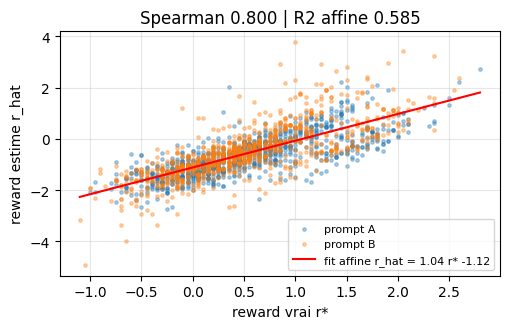

fit affine : r_hat ~= 1.044 * r* -1.117   (R2 = 0.585)
ecart-type de r_hat = 0.905 vs r* = 0.662


In [11]:
alpha_fit, beta_fit = np.polyfit(rs_test.flatten(), r_hat.flatten(), 1)
resid = r_hat.flatten() - (alpha_fit * rs_test.flatten() + beta_fit)
r2 = 1 - np.var(resid) / np.var(r_hat)

fig, ax = plt.subplots(figsize=(5.2, 3.4))
for p_val, nom, coul in [(0, 'prompt A', 'tab:blue'), (1, 'prompt B', 'tab:orange')]:
    m = (pr_test == p_val)
    mm = np.repeat(m, 2)
    ax.scatter(rs_test.flatten()[mm], r_hat.flatten()[mm], s=6, alpha=0.35,
               color=coul, label=nom)
xs = np.linspace(rs_test.min(), rs_test.max(), 50)
ax.plot(xs, alpha_fit * xs + beta_fit, 'r-', lw=1.5,
        label=f'fit affine r_hat = {alpha_fit:.2f} r* {beta_fit:+.2f}')
ax.set_xlabel('reward vrai r*'); ax.set_ylabel('reward estime r_hat')
ax.set_title(f'Spearman {rho:.3f} | R2 affine {r2:.3f}')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"fit affine : r_hat ~= {alpha_fit:.3f} * r* {beta_fit:+.3f}   (R2 = {r2:.3f})")
print(f"ecart-type de r_hat = {np.std(r_hat):.3f} vs r* = {np.std(rs_test):.3f}")

**Lecture du nuage.** La pente, l'interception et $R^2$ sont imprimés avec le graphique. $1-R^2$ représente la fraction de variance non expliquée par ce fit, sans être nécessairement du bruit. Les offsets entre prompts ne sont pas fixés par les comparaisons intra-prompt.

Le fit de cette exécution donne `r_hat ≈ 1,044 r* − 1,117`, avec `R²=0,585`. La pente proche de 1 est descriptive : elle n’identifie pas les offsets relatifs des prompts, invisibles aux comparaisons intra-prompt. La part non expliquée par ce fit vaut 0,415 ; elle ne s’identifie pas automatiquement à du bruit. L’écart-type des scores prédits vaut 0,905 contre 0,662 pour l’oracle : le diagramme conserve donc une information de dispersion que Spearman seul ne montre pas.


## 10. Identification : offsets par prompt

Une constante différente par prompt disparaît des différences intra-prompt. En revanche, multiplier les scores change les probabilités lorsque $\beta$ est fixé. Les deux contrôles suivants calculent effectivement ces écarts.

In [12]:
# Les offsets peuvent différer entre prompts, mais sont communs aux deux bras de chaque paire.
offsets = np.where(pr_test == 0, 5.0, -3.0)[:, None]
r_shift = r_hat + offsets
p_shift = 1.0 / (1.0 + np.exp(-(r_shift[:, 0] - r_shift[:, 1])))
p_scale = 1.0 / (1.0 + np.exp(-2.0 * (r_hat[:, 0] - r_hat[:, 1])))
ecart = float(np.max(np.abs(p_shift - p_hat)))
ecart_echelle = float(np.max(np.abs(p_scale - p_hat)))
assert ecart < 1e-6 and ecart_echelle > 1e-6
print(f"Offset par prompt +5/-3 : max |Δp| = {ecart:.3e}")
print(f"Échelle ×2 à beta fixé : max |Δp| = {ecart_echelle:.3f}, probabilités modifiées")

Offset par prompt +5/-3 : max |Δp| = 8.011e-08
Échelle ×2 à beta fixé : max |Δp| = 0.150, probabilités modifiées


### Exercice 2 : un juge plus bruité

Complétez `probabilite_juge`, puis régénérez les paires train/test avec $\beta=0,5$, réentraînez et comparez accuracy, référence Bayes, NLL et pente. Le bruit d'échantillonnage et la limite de capacité empêchent de garantir un ordre ou une pente observée.

Étapes : calculez la sigmoïde à partir de `beta * delta` ; vérifiez le cas nul et les signes opposés ; régénérez ensuite train/test et comparez les métriques au même protocole.

In [13]:
def probabilite_juge(delta, beta):
    # TODO étudiant : probabilité BT sigma(beta * delta)
    return None

if probabilite_juge(1., .5) is None:
    print("Exercice 2 à compléter : juge beta=0.5 puis nouvel entraînement.")
else:
    for d,b in [(0.,.5),(1.,.5),(-2.,.5),(2.,1.)]:
        x=probabilite_juge(d,b); assert x is not None and np.isfinite(x) and np.isclose(x,1/(1+np.exp(-b*d)))
    rng2=np.random.default_rng(0);calls=[0]
    def juge_controle(d,b):
        calls[0]+=1;return probabilite_juge(d,b)
    tr,yt,rt,pt=make_pairs(4000,rng2,beta=.5,prob_fn=juge_controle)
    te,ye,re,pe=make_pairs(1000,rng2,beta=.5,prob_fn=juge_controle)
    assert calls[0]==5000
    xt,xe=encode(tr,pt),encode(te,pe);torch.manual_seed(0);mm=RewardModel();hh=train_bt(mm,xt,yt)
    scores,probas,ac,br=predict_pairs(mm,xe,ye);p=1/(1+np.exp(-.5*(re[:,0]-re[:,1])))
    alpha,inter=np.polyfit(re.flatten(),scores.flatten(),1)
    nll=-np.mean(ye*np.log(probas+1e-12)+(1-ye)*np.log(1-probas+1e-12))
    print(f"{calls[0]} appels juge ; accuracy={ac:.3f}, Bayes attendu={np.mean(np.maximum(p,1-p)):.3f}, pente={alpha:.3f}, NLL test={nll:.4f}, Brier={br:.4f}")

Exercice 2 à compléter : juge beta=0.5 puis nouvel entraînement.


## 11. Multi-seed : stabilité de la boucle

Quatre runs complets pour les graines 0, 1, 7 et 42 régénèrent données et juge, et réinitialisent les paramètres et l’ordre des lots. La dispersion est celle du pipeline de bout en bout, pas seulement celle de l'initialisation.

In [14]:
def run_seed(seed, n_train=4000, n_test=1000):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    tr, ytr, rstr, ptr = make_pairs(n_train, rng)
    te, yte, rste, pte = make_pairs(n_test, rng)
    xtr, xte = encode(tr, ptr), encode(te, pte)
    d = rste[:, 0] - rste[:, 1]
    p_t = 1.0 / (1.0 + np.exp(-d))
    m = RewardModel()
    h = train_bt(m, xtr, ytr)
    r_h, p_h, a, b = predict_pairs(m, xte, yte)
    _, _, a_tr, _ = predict_pairs(m, xtr, ytr)
    sp, _ = spearmanr(r_h.flatten(), rste.flatten())
    return dict(seed=seed, acc=a, acc_tr=a_tr,
                bayes=float(np.mean(np.maximum(p_t, 1 - p_t))),
                brier=b, brier_bayes=float(np.mean(p_t * (1 - p_t))),
                rho=float(sp), lossf=h[-1])


res = [run_seed(s) for s in SEEDS]
print(f"{'seed':>4} {'acc_tr':>7} {'acc':>6} {'bayes':>6} {'ecart':>7} {'brier':>7} {'planch':>7} "
      f"{'rho':>6} {'lossf':>6}")
for r in res:
    print(f"{r['seed']:>4} {r['acc_tr']:>7.3f} {r['acc']:>6.3f} {r['bayes']:>6.3f} "
          f"{r['acc'] - r['bayes']:>+7.3f} {r['brier']:>7.4f} {r['brier_bayes']:>7.4f} "
          f"{r['rho']:>6.3f} {r['lossf']:>6.3f}")

g = lambda k: np.mean([r[k] for r in res])
s = lambda k: np.std([r[k] for r in res])
print(f"\nmoyennes : acc {g('acc'):.3f} +- {s('acc'):.3f} (Bayes {g('bayes'):.3f}, "
      f"train {g('acc_tr'):.3f}) | Brier {g('brier'):.4f} (plancher {g('brier_bayes'):.4f}) "
      f"| rho {g('rho'):.3f} | perte {g('lossf'):.3f}")

seed  acc_tr    acc  bayes   ecart   brier  planch    rho  lossf
   0   0.704  0.665  0.702  -0.037  0.2259  0.2012  0.800  0.574
   1   0.696  0.663  0.695  -0.032  0.2289  0.2049  0.801  0.587
   7   0.699  0.639  0.693  -0.054  0.2283  0.2053  0.801  0.584
  42   0.681  0.671  0.693  -0.022  0.2110  0.2057  0.814  0.600

moyennes : acc 0.659 +- 0.012 (Bayes 0.696, train 0.695) | Brier 0.2235 (plancher 0.2042) | rho 0.804 | perte 0.586


**Lecture multi-seed.** La table affiche pour chaque graine accuracy train/test, référence de Bayes attendue, Brier et sa référence $E[p(1-p)]$, Spearman et perte. Les moyennes et écarts-types résument quatre expériences complètes ; elles ne démontrent pas une propriété structurelle de la BCE.

Les quatre runs donnent une accuracy moyenne **0,659 ± 0,012** et un Brier moyen **0,2235**, référence **0,2042**.

### Exercice 3 : budget d'étiquettes

Complétez `indices_proches`, puis générez un réservoir de **8000** paires et comparez **1500** paires aléatoires à **1500** proches sur le même test. Entraînez deux modèles et mesurez accuracy et Spearman, sans supposer un gagnant.

Étapes : triez les indices par écart absolu avec départage stable ; sélectionnez le budget sans doublon ; entraînez et comparez les deux politiques sur le test commun.

In [15]:
def indices_proches(deltas, budget):
    # TODO étudiant : indices des plus petits |delta|, ordre stable
    return None

if indices_proches(np.array([.9,.4,.7]),2) is None:
    print("Exercice 3 à compléter : sélection proche puis comparaison sur 8000 candidats.")
else:
    for d,k,attendu in [(np.array([.9,.4,.7]),2,[1,2]),(np.array([-.8,.3,-.4,.9]),3,[1,2,0])]:
        x=indices_proches(d,k); assert x is not None and list(x)==attendu
    rng3=np.random.default_rng(0);pool,yp,rp,pr=make_pairs(8000,rng3);delta=rp[:,0]-rp[:,1]
    proche=np.asarray(indices_proches(delta,1500));attendu=np.argsort(np.abs(delta),kind='stable')[:1500]
    assert proche.shape==(1500,) and np.array_equal(proche,attendu)
    hasard=rng3.choice(8000,1500,replace=False)
    for nom,ids in [('aléatoire',hasard),('proche',proche)]:
        pairs=[pool[int(j)] for j in ids];xx=encode(pairs,pr[ids]);torch.manual_seed(0);mm=RewardModel();train_bt(mm,xx,yp[ids]);sc,pp,ac,br=predict_pairs(mm,x_test,y_test);rr,_=spearmanr(sc.flatten(),rs_test.flatten());print(f"{nom}: 1500 paires, accuracy={ac:.3f}, Spearman={rr:.3f}, Brier={br:.4f}")

Exercice 3 à compléter : sélection proche puis comparaison sur 8000 candidats.


## À retenir

| Question | Résultat |
|---|---|
| Signal de préférence | Bradley–Terry compare les deux scores ; le bras gagnant vaut `1-y`. |
| Références | Accuracy Bayes en espérance et Brier $E[p(1-p)]$. |
| Limite architecturale | Le pooling moyen ignore l'ordre et ne peut apprendre le bonus positionnel. |
| Identification | Un offset par prompt est invisible, une échelle modifiée ne l'est pas à beta fixé. |
| Dispersion | Quatre graines régénèrent les données et relancent l’entraînement complet. |

## Exercices

1. [Régulariser le score](#Exercice-1-:-régulariser-le-score) : définir une pénalité différentiable et comparer trois intensités sur les mêmes données.
2. [Un juge plus bruité](#Exercice-2-:-un-juge-plus-bruité) : modifier la température du juge puis réévaluer les références et le modèle.
3. [Budget d'étiquettes](#Exercice-3-:-budget-d'étiquettes) : sélectionner des paires proches et comparer leur intérêt à un échantillon aléatoire.

## Conclusion

La vraie boucle optimise un modèle de reward sur des préférences bruitées. Les scores, références en espérance et graphiques permettent de distinguer capacité, calibration et dispersion ; la preuve de permutation expose une limite structurelle de cette architecture. La suite branche un reward sur une politique.

Sur quatre graines complètes, l’accuracy vaut 0,659 ± 0,012, face à une référence Bayes attendue moyenne de 0,696. Le Brier moyen 0,2235 se compare à la référence attendue E[p(1−p)]=0,2042. La comparaison des métriques, du pooling invariant par permutation et des probabilités sous translation permet de distinguer les limites : capacité pour le bonus positionnel, calibration sur ce test et offsets non identifiables.

La suite change de question : [RLPT-00b](RLPT-00b-Biais-Dataset-Preferences-Python.ipynb) étudie les biais des préférences, [RLPT-00d](RLPT-00d-Reward-Trainer-TRL-Python.ipynb) reprend l’entraînement dans TRL, et [RLPT-01](RLPT-01-PPO-RLHF-Petit-Modele-Python.ipynb) optimise une politique contre un reward.


## Vérifiez votre compréhension

1. Pourquoi le Brier Bayes vaut-il $p(1-p)$ ?
2. Pourquoi le modèle ne sait-il pas distinguer deux permutations à prompt fixé ?
3. Quel changement de score préserve les probabilités BT ?

<details><summary>Réponses</summary>

1. C'est l'espérance de $(p-y)^2$ pour $y$ Bernoulli($p$).
2. La moyenne des embeddings de tokens est invariante à l'ordre ; la somme des positions est constante.
3. Une translation propre à chaque prompt disparaît des différences ; une multiplication ne disparaît pas à beta fixé.

</details>

## Pour aller plus loin

- [RLPT-00b — Biais des préférences](RLPT-00b-Biais-Dataset-Preferences-Python.ipynb).
- [RLPT-00d — RewardTrainer](RLPT-00d-Reward-Trainer-TRL-Python.ipynb).
- [RLPT-01 — PPO-RLHF](RLPT-01-PPO-RLHF-Petit-Modele-Python.ipynb).
- Références : Bradley et Terry (1952), Christiano et al. (2017), Ouyang et al. (2022), voir [index RL](../README.md#références).

- [FT-04 — RLHF et DPO](../../GenAI/FineTuning/FT-04-RLHF-DPO-Python.ipynb) : relier les préférences au post-entraînement de modèles de langage.